# Neutron Source Demo

In [1]:
from pathlib import Path
import sys
from fusion_fuel_concepts_explorer.sources import SteadyStateSource


## Single DT Example

DT source considering average density and temperature


SteadyStateSource(
  source_type='DT',
  volume_m3=150.0,
  n_i=1e+20,
  T_i=14.0,
  tau_p=1.0,
  tau_p_D=None,
  tau_p_T=None,
  tau_p_He3=None,
  tau_p_He4=None,
  solver_tol=1e-10,
  solver_maxfev=500,
  input_fractions={'D': 0.5, 'T': 0.5, 'He3': 0.0, 'He4': 0.0, 'imp': 0.0},
  rho_grid_profile=array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ]),
  total_density_m3_pro

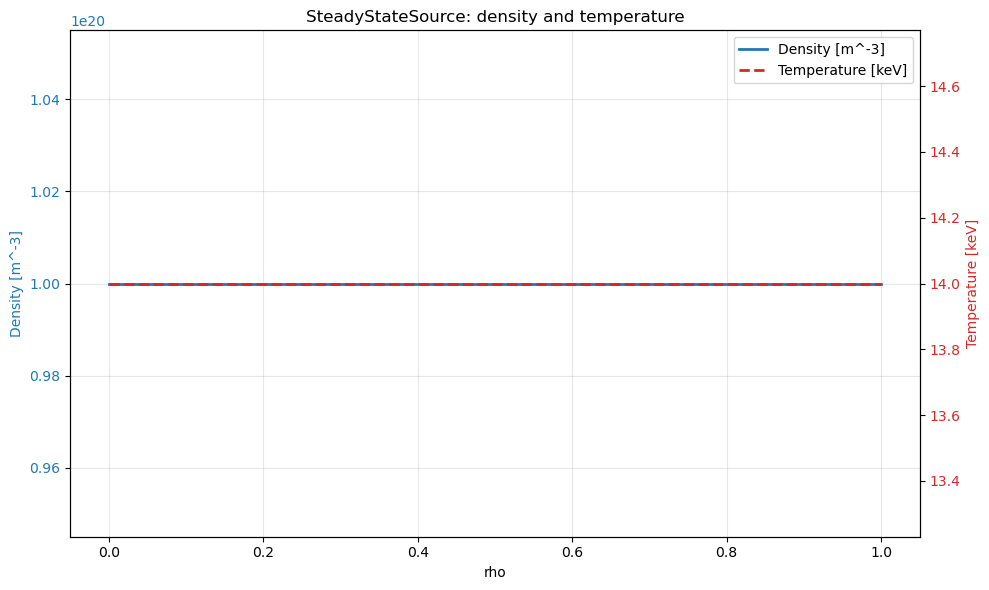

In [2]:
solver = SteadyStateSource(
    source_type="DT",
    volume_m3=150.0,
    n_i=1e20,
    T_i=14.0,
    tau_p=1.0,
)

print(solver)
print(f"\nAverage density [m^-3]: {solver.average_density_m3:.6g}")
print(f"Average temperature [keV]: {solver.average_temperature_keV:.6g}")
print(f"Total fusion power [W]: {solver.total_fusion_power_W:.6g}")

# print OpenMC neutron energies [eV] and emission probabilities for [DT, DDn, TT, THe3n]
print(f"Neutron energies [eV]: {solver.neutron_energies_eV}")
print(f"neutron emission probabilities: {solver.neutron_emission_probabilities}")

fig, ax = solver.plot() # plots density and temperature over normalized radius



SteadyStateSource(
  source_type='DHe3',
  volume_m3=150.0,
  n_i=<function <lambda> at 0x7f04d8f76a20>,
  T_i=<function <lambda> at 0x7f04d8f768e0>,
  tau_p=1.0,
  tau_p_D=None,
  tau_p_T=None,
  tau_p_He3=None,
  tau_p_He4=None,
  solver_tol=1e-10,
  solver_maxfev=500,
  input_fractions={'D': 0.5, 'T': 0.0, 'He3': 0.5, 'He4': 0.0, 'imp': 0.0},
  rho_grid_profile=array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 

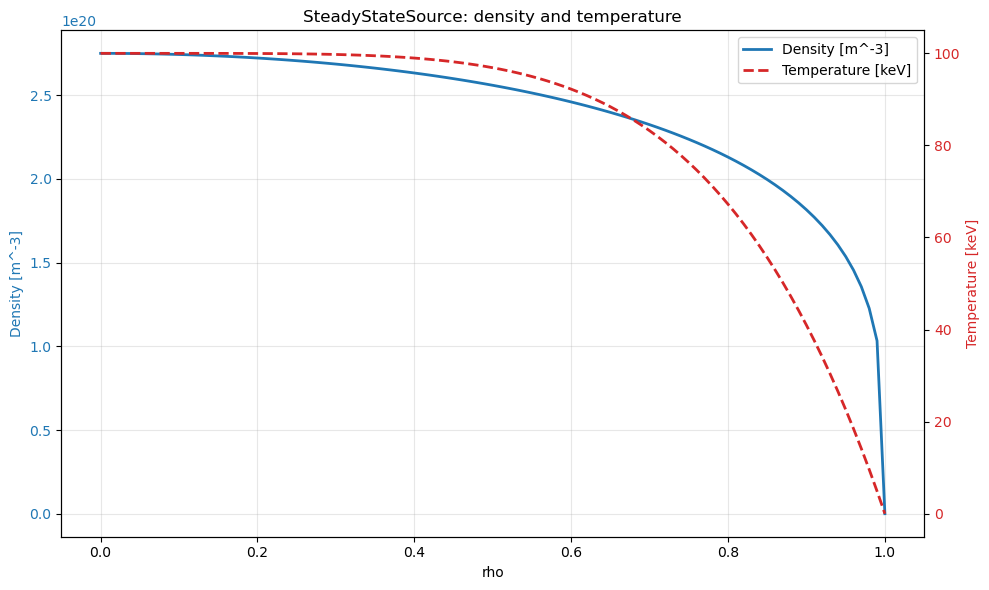

In [3]:
# try density and temperature profiles
# Standard peaking profile:
# n(rho) = n_avg * p * (1-rho^2)^(p-1)
# This keeps <n>_rho = n_avg with 2*rho weighting and gives n(1)=0.
avg_density = 2.2e20
density_peaking = 1.25
max_temperature = 100.0
density_profile = lambda rho: avg_density * density_peaking * ((1.0 - rho**2.0) ** (density_peaking - 1.0))
temperature_profile = lambda r: max_temperature * (1 - (r / 1.0) ** 5)

solver = SteadyStateSource(
    source_type="DHe3",
    volume_m3=150.0,
    n_i=density_profile,
    T_i=temperature_profile,
    tau_p=1.0,
)
print(solver)

# print OpenMC neutron energies [eV] and emission probabilities for [DT, DDn, TT, THe3n]
print(f"Neutron energies [eV]: {solver.neutron_energies_eV}")
print(f"neutron emission probabilities: {solver.neutron_emission_probabilities}")

fig, ax = solver.plot()

# Find DT and DHe3 operating points

## DT

In [4]:
# try density and temperature profiles
# Standard peaking profile:
# n(rho) = n_avg * p * (1-rho^2)^(p-1)
# This keeps <n>_rho = n_avg with 2*rho weighting and gives n(1)=0.
avg_density = 1.3e20
avg_temperature = 14.0
temperature_center_max = 30.0
temperature_center_min = 25.0
density_center_max = 2e20
density_center_min = 1.5e20
density_profile = lambda rho: avg_density * density_peaking * ((1.0 - rho**2.0) ** (density_peaking - 1.0))
temperature_profile = lambda rho: avg_temperature * temperature_peaking * ((1.0 - rho**2.0) ** (temperature_peaking - 1.0))

Found peaking factors: density_peaking=1.1683333333333334, temperature_peaking=1.8358333333333332
Total fusion power [W]: 5.43043e+08
Max temperature [keV]: 25.7017 Max density [m^-3]: 1.51883e+20
Found peaking factors: density_peaking=1.1683333333333334, temperature_peaking=1.91
Total fusion power [W]: 5.48083e+08
Max temperature [keV]: 26.74 Max density [m^-3]: 1.51883e+20


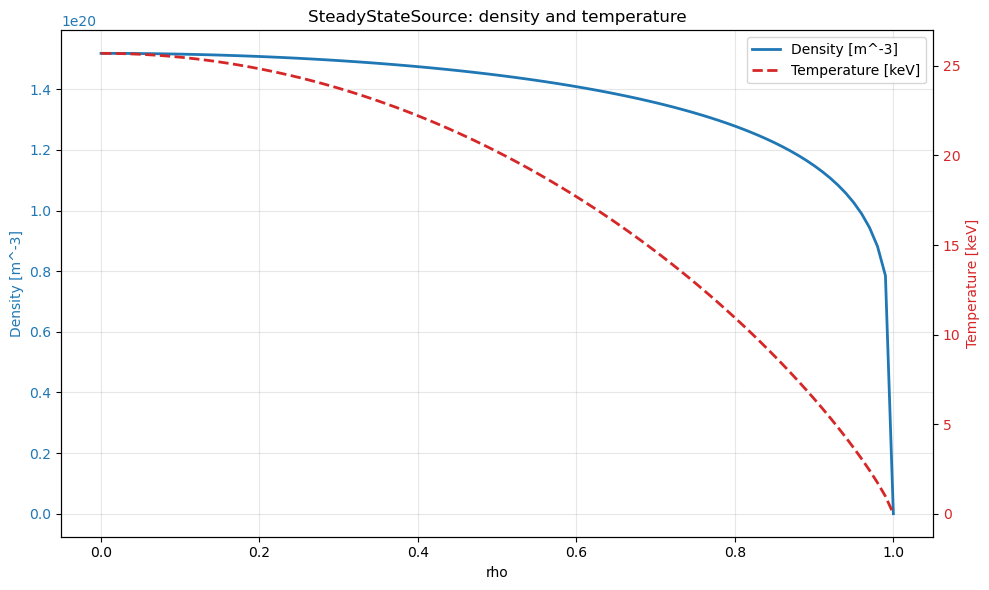

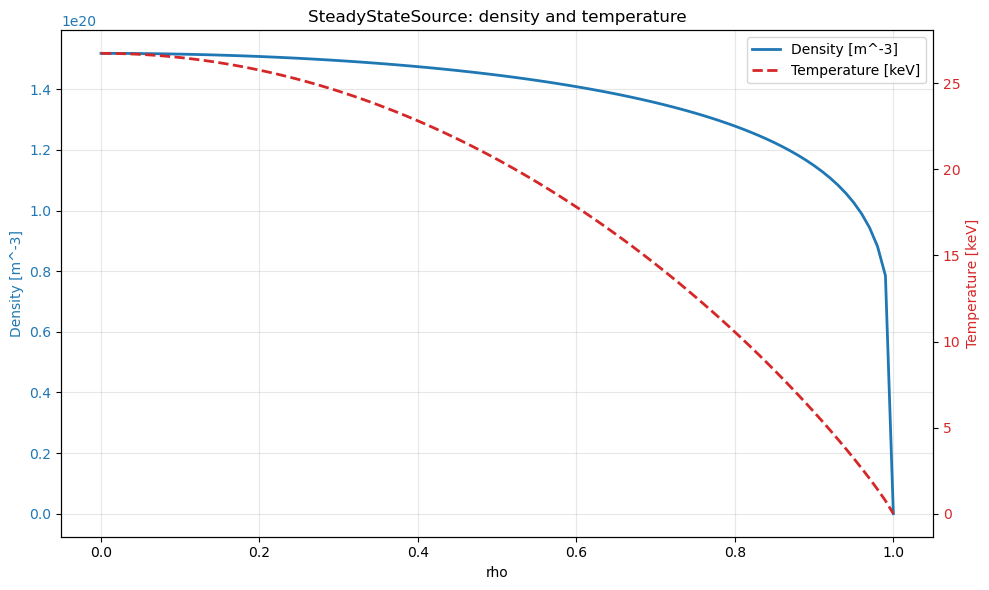

In [5]:
flag = False

import numpy as np
for density_peaking in np.linspace(1.02, 2.8, 25):
    for temperature_peaking in np.linspace(1.02, 2.8, 25):
        solver = SteadyStateSource(
            source_type="DT",
            volume_m3=150.0,
            n_i=density_profile,
            T_i=temperature_profile,
            tau_p=1.0,
        )
        if abs(solver.total_fusion_power_W - 500e6) < 50e6:
            if temperature_profile(0.0) < temperature_center_max and temperature_profile(0.0) > temperature_center_min:
                if density_profile(0.0) < density_center_max and density_profile(0.0) > density_center_min:
                    print(f"Found peaking factors: density_peaking={density_peaking}, temperature_peaking={temperature_peaking}")
                    print(f"Total fusion power [W]: {solver.total_fusion_power_W:.6g}")
                    print(f"Max temperature [keV]: {temperature_profile(0.0):.6g} Max density [m^-3]: {density_profile(0.0):.6g}")
                    solver.plot()
                    flag = True
                    
if not flag:
    print("No peaking factors found that meet the criteria.")


## DHe3

In [14]:
# try density and temperature profiles
# Standard peaking profile:
# n(rho) = n_avg * p * (1-rho^2)^(p-1)
# This keeps <n>_rho = n_avg with 2*rho weighting and gives n(1)=0.
avg_density = 1.3e20
avg_temperature = 70.0
temperature_center_max = 100.0
temperature_center_min = 70.0
density_center_max = 4e20
density_center_min = 1.5e20
density_profile = lambda rho: avg_density * density_peaking * ((1.0 - rho**2.0) ** (density_peaking - 1.0))
temperature_profile = lambda rho: avg_temperature * temperature_peaking * ((1.0 - rho**2.0) ** (temperature_peaking - 1.0))

Found peaking factors: density_peaking=2.6295833333333336, temperature_peaking=1.38375
Total fusion power [W]: 4.61958e+08
Max temperature [keV]: 96.8625 Max density [m^-3]: 3.41846e+20
Found peaking factors: density_peaking=2.7541666666666664, temperature_peaking=1.38375
Total fusion power [W]: 4.81208e+08
Max temperature [keV]: 96.8625 Max density [m^-3]: 3.58042e+20
Found peaking factors: density_peaking=2.87875, temperature_peaking=1.2591666666666668
Total fusion power [W]: 4.61648e+08
Max temperature [keV]: 88.1417 Max density [m^-3]: 3.74238e+20
Found peaking factors: density_peaking=2.87875, temperature_peaking=1.38375
Total fusion power [W]: 5.00425e+08
Max temperature [keV]: 96.8625 Max density [m^-3]: 3.74238e+20
Found peaking factors: density_peaking=3.0033333333333334, temperature_peaking=1.2591666666666668
Total fusion power [W]: 4.78816e+08
Max temperature [keV]: 88.1417 Max density [m^-3]: 3.90433e+20
Found peaking factors: density_peaking=3.0033333333333334, temperature

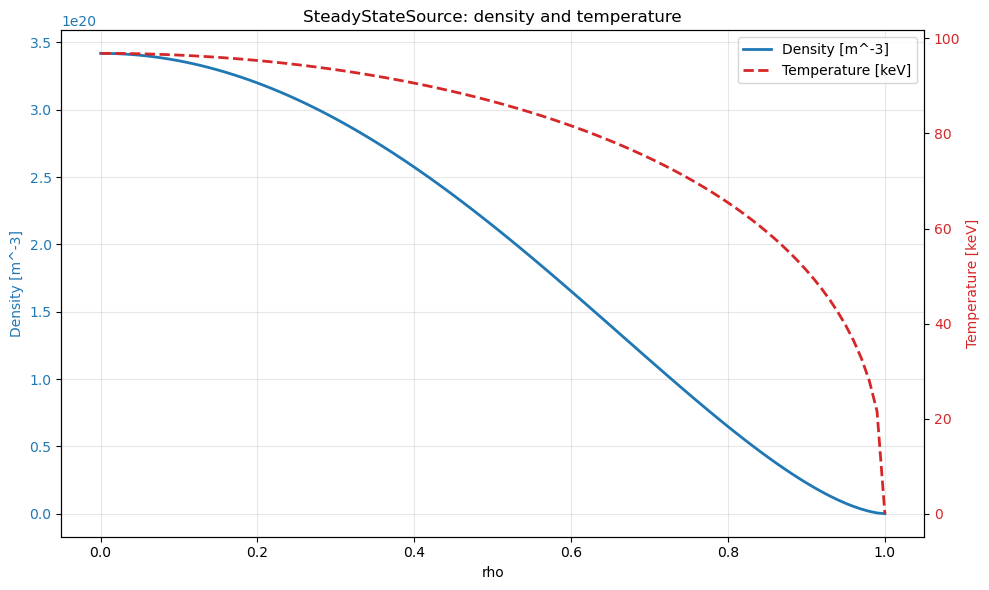

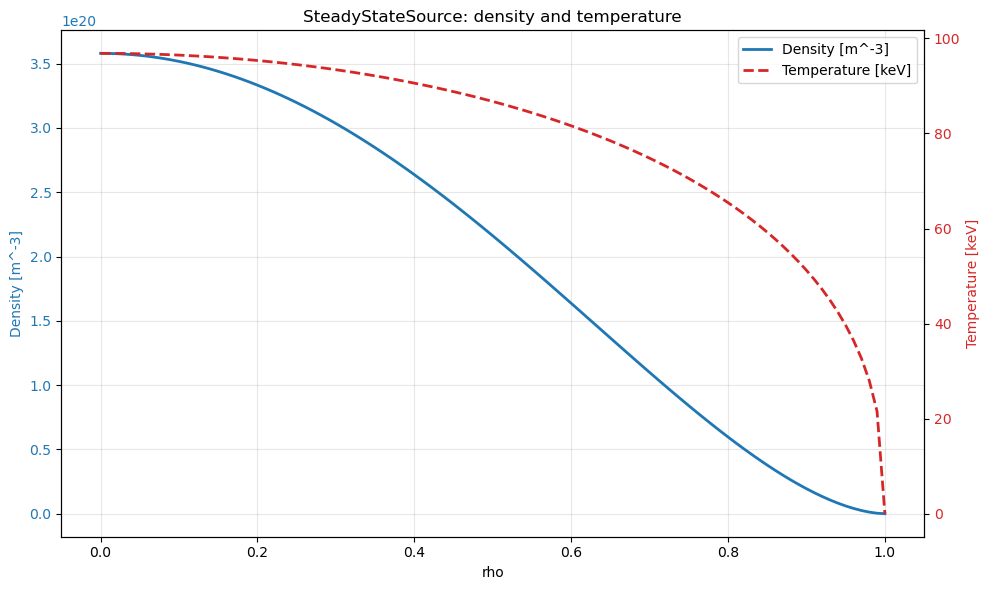

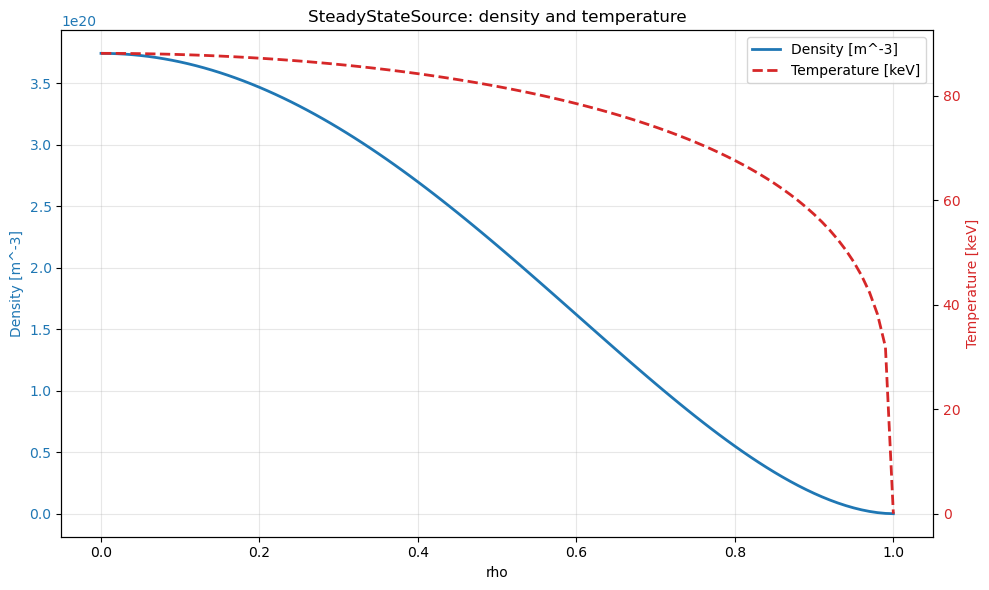

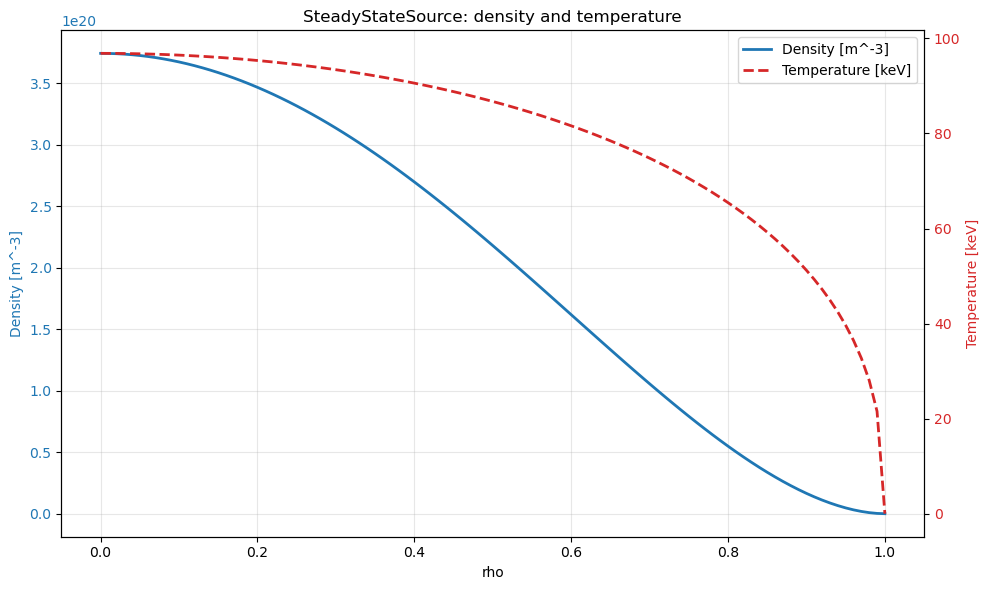

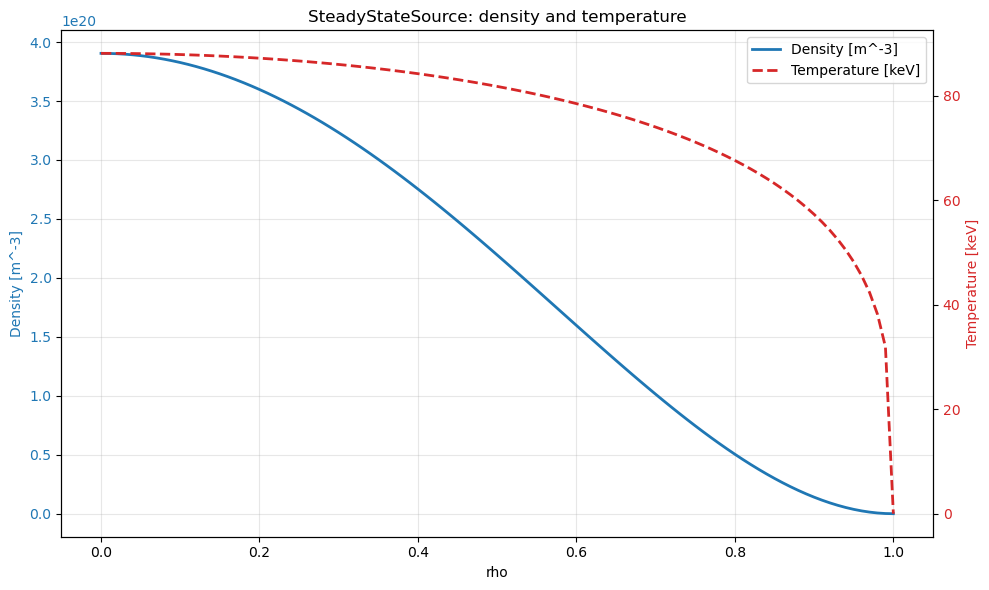

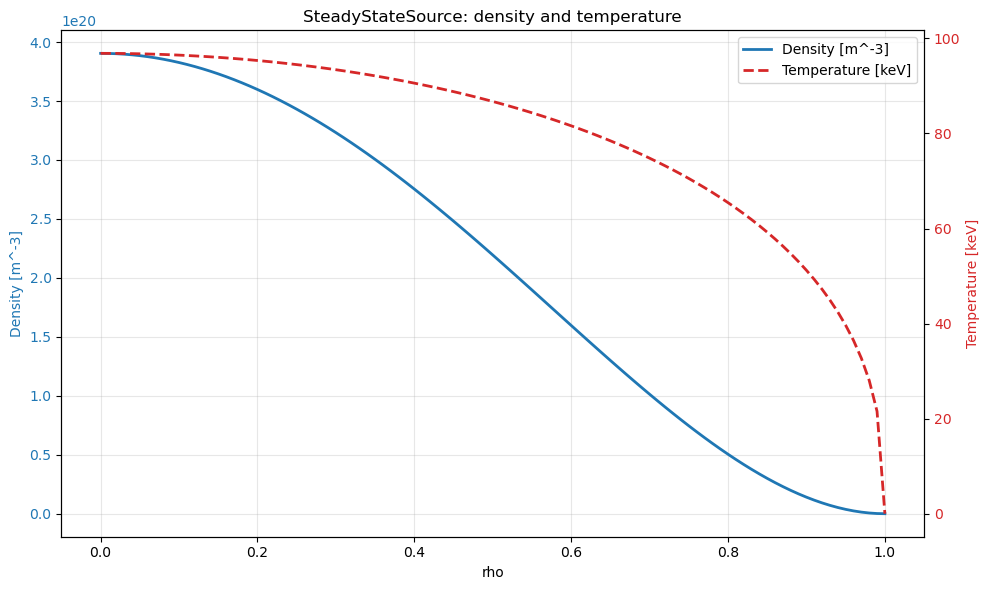

In [15]:
flag = False

import numpy as np
for density_peaking in np.linspace(1.01, 4, 25):
    for temperature_peaking in np.linspace(1.01, 4, 25):
        solver = SteadyStateSource(
            source_type="DHe3",
            volume_m3=150.0,
            n_i=density_profile,
            T_i=temperature_profile,
            tau_p=1.0,
        )
        if abs(solver.total_fusion_power_W - 500e6) < 50e6:
            if temperature_profile(0.0) < temperature_center_max and temperature_profile(0.0) > temperature_center_min:
                if density_profile(0.0) < density_center_max and density_profile(0.0) > density_center_min:
                    print(f"Found peaking factors: density_peaking={density_peaking}, temperature_peaking={temperature_peaking}")
                    print(f"Total fusion power [W]: {solver.total_fusion_power_W:.6g}")
                    print(f"Max temperature [keV]: {temperature_profile(0.0):.6g} Max density [m^-3]: {density_profile(0.0):.6g}")
                    solver.plot()
                    flag = True
                    
if not flag:
    print("No peaking factors found that meet the criteria.")
